## FSHD test: case ONT019

In [14]:
##### Basic information #####
PREFIX="ONT019"

In [15]:
### Importing modules ###
import os
import multiprocessing
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### DIRECTORIES ###
TMP = "/raid/tmp/fshd"
QUERY = "/lab_nas_home_user/Mark/FSHD/querySeq"

### Resources ###
cores = int(multiprocessing.cpu_count() * 0.75)

### Softwares ###
BLASTN = "/Everythings/misc/ncbi-blast-2.13.0+/bin/blastn"
MAKEBLASTDB = "/Everythings/misc/ncbi-blast-2.13.0+/bin/makeblastdb"
MODKIT = "/Everythings/misc/modkit_v0.2.4/modkit"

In [16]:
### Path to BAM file ###
directory="/nanopore_nas/nanopore_pipeline"
#matching_folder = next(folder for folder in os.listdir(directory) if PREFIX in folder)
BAM = "/gene_lv/NGS_gene_lv_Storage/WGS/analysis/pipeline_output/WGS-ONT/WGS-ONT019-5657831-D23881/WGS-ONT019-5657831-D23881_sup_Q13_20241101/OUTPUT/43.longphase/WGS-ONT019-5657831-D23881.sorted.phased.bam"

In [17]:
### Prettify the output ###
blast_title = ['QuerySeq-id', 'Seq-id', 'Identity%', 'Alignment-length', 'Mismatches', 'Gap', 'Q.Start', 'Q.End', 'S.Start', 'S.End', 'E-value', 'Bit-score']

In [18]:
### Create fasta file from BAM file, extract reads mapped to chr4 ###
os.system("samtools view -b "+BAM+" chr4 | samtools fasta - > "+TMP+"/"+PREFIX+"_chr4.fasta")

[W::hts_idx_load3] The index file is older than the data file: /gene_lv/NGS_gene_lv_Storage/WGS/analysis/pipeline_output/WGS-ONT/WGS-ONT019-5657831-D23881/WGS-ONT019-5657831-D23881_sup_Q13_20241101/OUTPUT/43.longphase/WGS-ONT019-5657831-D23881.sorted.phased.bam.bai
[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 739432 reads


0

In [19]:
### Create BLAST database ###
os.system(MAKEBLASTDB+" -in "+TMP+"/"+PREFIX+"_chr4.fasta -dbtype nucl -out "+TMP+"/blastdb/chr4 -title "+PREFIX)



Building a new DB, current time: 12/12/2024 16:52:59
New DB name:   /raid/tmp/fshd/blastdb/chr4
New DB title:  ONT019
Sequence type: Nucleotide
Deleted existing Nucleotide BLAST database named /raid/tmp/fshd/blastdb/chr4
Keep MBits: T
Maximum file size: 3000000000B
Adding sequences from FASTA; added 739432 sequences in 31.4307 seconds.




0

Get sequence ID with tail sequence (pLAM)

In [20]:
### Find reads have tail sequence (pLAM) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/pLAM.fasta -out "+TMP+"/"+PREFIX+"_pLAM.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
pLAM_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_pLAM.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)
pLAM_blast.head()

,Seq-id,Identity%,Alignment-length,Mismatches,Gap,Q.Start,Q.End,S.Start,S.End,E-value,Bit-score
0,dc22011f-bbea-4c7c-80a1-84490fdfa308,100.000,200,0,0,1,200,1849,1650,3.210000e-100,370
1,8c928f77-fcea-4d87-8b1f-6a8e6eef4237,100.000,200,0,0,1,200,248,49,3.210000e-100,370
2,0cd22bfb-fefe-4e7b-9fea-681d3d24ae39,98.000,200,1,2,1,200,709,905,1.950000e-92,344
3,a5f6a3a4-ddd9-448e-acc2-a3c6b53b3b59,96.500,200,6,1,1,200,30457,30655,5.450000e-88,329
4,49d0a653-2001-44ef-aaf9-ffbba9ea39bb,84.577,201,30,1,1,200,2319,2519,1.600000e-48,198


Get sequence ID with head sequence (P13E11)

In [21]:
### Find reads have head sequence (P13E11) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/P13E11.fasta -out "+TMP+"/"+PREFIX+"_P13E11.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
P13E11_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_P13E11.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)
P13E11_blast.head()

,Seq-id,Identity%,Alignment-length,Mismatches,Gap,Q.Start,Q.End,S.Start,S.End,E-value,Bit-score
0,4f8d1820-c703-40b2-bcef-22c7f1038584,100.0,220,0,0,1,220,103,322,2.740000e-111,407
1,d02f1065-9fe8-403d-ab77-94bb3c65c054,100.0,220,0,0,1,220,20867,20648,2.740000e-111,407
2,5fcc7acf-53b0-47b5-b08b-62fbb8dabad4,100.0,220,0,0,1,220,7042,7261,2.740000e-111,407
3,3b7b120d-cfa1-4119-9ca7-635edd9213c7,100.0,220,0,0,1,220,13292,13073,2.740000e-111,407
4,74f2adbf-e36c-4d73-9909-e3acc4dfc685,100.0,220,0,0,1,220,5430,5211,2.740000e-111,407


Count D4Z4 repeat units

In [22]:
### Find reads have D4Z4 ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/MIR8078.fasta -out "+TMP+"/"+PREFIX+"_D4Z4.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
D4Z4_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_D4Z4.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)

# Count number of reads, grouped by Seq-id
D4Z4_count = D4Z4_blast.groupby('Seq-id').size().reset_index(name='Count').sort_values(by='Count', ascending=False)

Count D4Z4 repeats having **EITHER head OR tail**

In [23]:
# Find unique sequences from the first column of both pLAM_blast and P13E11_blast
unique_sequences = set(pLAM_blast['Seq-id']).union(set(P13E11_blast['Seq-id']))

if len(unique_sequences) == 0:
    print("No unique sequences found.")
else:
    # Extract rows from D4Z4_count where Seq-id is in unique_sequences
    count_head_or_tail = D4Z4_count[D4Z4_count['Seq-id'].isin(unique_sequences)]
    count_head_or_tail.head()

Count D4Z4 repeats having **BOTH head AND tail**

In [24]:
# Find sequences from the first column in both pLAM_blast and P13E11_blast
common_sequences = set(pLAM_blast['Seq-id']).intersection(set(P13E11_blast['Seq-id']))

if len(common_sequences) == 0:
    print("No common sequences found.")
else: 
    # Extract rows from D4Z4_count where Seq-id is in common_sequences
    count_head_and_tail = D4Z4_count[D4Z4_count['Seq-id'].isin(common_sequences)]
    count_head_and_tail.head()

Check polyA tail

In [25]:
### Find reads have tail sequence (pLAM) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/pLAM-polyA.fasta -out "+TMP+"/"+PREFIX+"_pLAM_polyA.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
pLAM_polyA_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_pLAM_polyA.blast", header=None, sep="\t", names=blast_title)
        .sort_values(by='Identity%', ascending=False)
)

# Pivot the dataframe to have hapA and hapB mismatches in separate columns
pivot_df = pLAM_polyA_blast.pivot(index='Seq-id', columns='QuerySeq-id', values='Mismatches')
pivot_df.rename(columns={'hapA': 'hapA.Mismatches', 'hapB': 'hapB.Mismatches'}, inplace=True)

# Calculate the difference in mismatches between hapA and hapB
pivot_df['delta.Mismatches'] =  pivot_df['hapB.Mismatches'] - pivot_df['hapA.Mismatches']

# Permissive column to indicate if the sequence is hapA, hapB, or unknown
pivot_df['Permissive'] = pivot_df['delta.Mismatches'].apply(lambda x: 'hapA' if x == 1 else 'hapB' if x == -1 else 'Unknown')

# Reset the index to make 'Seq-id' a column again
result_df = pivot_df.reset_index()
result_df.columns.name = None

# Display the result
result_df.head()

,Seq-id,hapA.Mismatches,hapB.Mismatches,delta.Mismatches,Permissive
0,0cd22bfb-fefe-4e7b-9fea-681d3d24ae39,1,2,1,hapA
1,1a63c0b8-0193-40d7-81ce-8419f9c61b25,33,32,-1,hapB
2,49d0a653-2001-44ef-aaf9-ffbba9ea39bb,30,29,-1,hapB
3,4c3910a3-ea81-4dd8-bf59-ca314a57258d,31,30,-1,hapB
4,8c121b99-6f90-4035-939a-9dfa4235f936,32,31,-1,hapB


Calculate methylation level

In [26]:
### Extract reads with tail by sequence ID from pLAM_blast ###
pLAM_blast['Seq-id'].to_csv(TMP + "/" + PREFIX + "_tail_ids.txt", index=False, header=False)
os.system("samtools view -b -@ "+str(cores)+" --qname-file "+TMP+"/"+PREFIX+"_tail_ids.txt "+BAM+" > "+TMP+"/"+PREFIX+"_tail.bam")
os.system("samtools index "+TMP+"/"+PREFIX+"_tail.bam")
os.system("rsync -a "+TMP+"/"+PREFIX+"_tail.bam* /lab_nas_home_user/Mark/FSHD/tail_bams/")

### Extract CpG methylation information ###
os.system(MODKIT+" pileup "+TMP+"/"+PREFIX+"_tail.bam "+TMP+"/"+PREFIX+"_CpG.txt --cpg --ignore h --combine-strands --ref /lab_nas_home_user/Mark/reference_genome/hg38/genome.fasta")

> calculated chunk size: 6, interval size 100000, processing 600000 positions concurrently
> ignoring mod code h
> filtering to only CpG motifs
> attempting to sample 10042 reads
> Threshold of 0.5966797 for base C is very low. Consider increasing the filter-percentile or specifying a higher threshold.
> Done, processed 2940 rows. Processed ~9 reads and skipped zero reads.


0

In [27]:
cpg_title=["chrom", "start", "end", "score", "N_validCov", "N_mod", "FracMod"]
cpg = pd.read_table(TMP+"/"+PREFIX+"_CpG.txt", header=None, sep="\s+").iloc[:, [0, 1, 2, 4, 9, 11, 10]]
cpg.columns = cpg_title
cpg.head()

,chrom,start,end,score,N_validCov,N_mod,FracMod
0,chr4,190053909,190053910,1,1,0,0.0
1,chr4,190054024,190054025,1,1,0,0.0
2,chr4,190054044,190054045,1,1,0,0.0
3,chr4,190054090,190054091,1,1,1,100.0
4,chr4,190054249,190054250,1,1,0,0.0


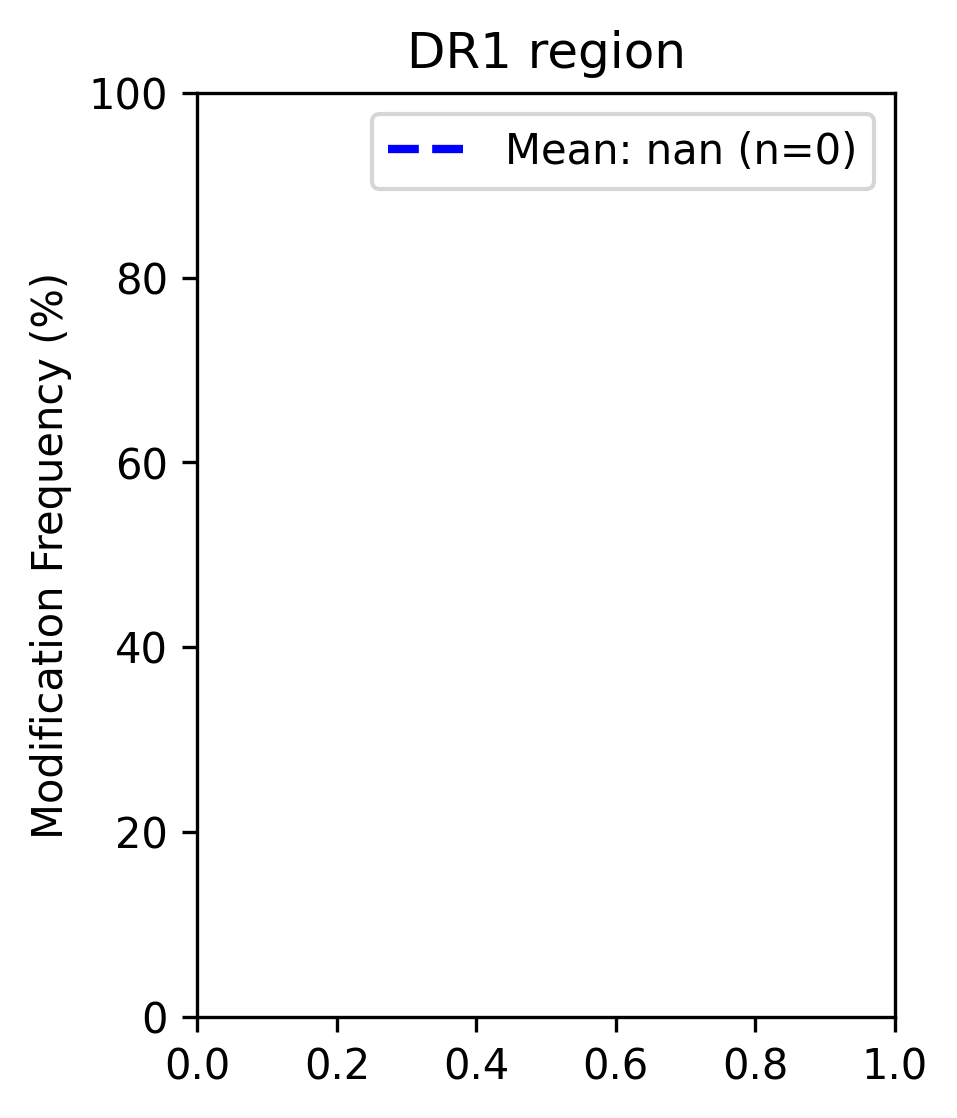

In [28]:
# DR1 region (hg38, chr4:190086470-190086723)
dr1_region = cpg[(cpg['chrom'] == 'chr4') & (cpg['start'] >= 190086470) & (cpg['end'] <= 190086723)]

# Remove rows where N_validCov is equal to 1
dr1_region_filtered = dr1_region[dr1_region['N_validCov'] != 1]

plt.figure(figsize=(3, 4), dpi=300)
sns.boxplot(y='FracMod', data=dr1_region_filtered, orient='v')
plt.title('DR1 region')
plt.ylabel('Modification Frequency (%)')
plt.ylim(0, 100)  # Set y-axis range from 0 to 100

# Calculate the mean value of FracMod
mean_fracmod_dr1 = dr1_region_filtered['FracMod'].mean()

# Add a red horizontal line at the mean value
plt.axhline(mean_fracmod_dr1, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_fracmod_dr1:.2f} (n={len(dr1_region_filtered)})')
plt.legend()

plt.show()


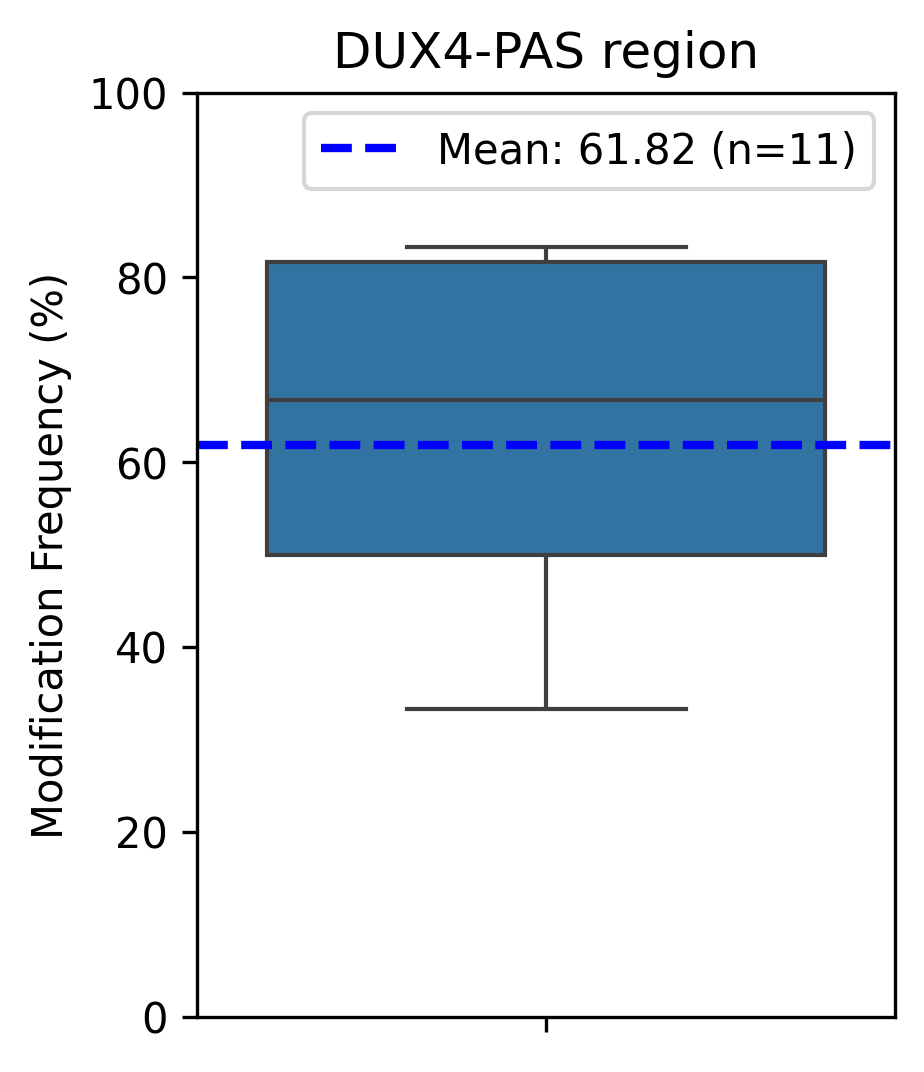

In [29]:
# DUX4-PAS region (hg38, chr4:190175600-190175834)
dux4pas = cpg[(cpg['chrom'] == 'chr4') & (cpg['start'] >= 190175600) & (cpg['end'] <= 190175834)]

# Remove rows where N_validCov is equal to 1
dux4pas_filtered = dux4pas[dux4pas['N_validCov'] != 1]

plt.figure(figsize=(3, 4), dpi=300)
sns.boxplot(y='FracMod', data=dux4pas_filtered, orient='v')
plt.title('DUX4-PAS region')
plt.ylabel('Modification Frequency (%)')
plt.ylim(0, 100)  # Set y-axis range from 0 to 100

# Calculate the mean value of FracMod
mean_fracmod = dux4pas_filtered['FracMod'].mean()

# Add a red horizontal line at the mean value
plt.axhline(mean_fracmod, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_fracmod:.2f} (n={len(dux4pas_filtered)})')
plt.legend()

plt.show()


In [30]:
### Remove tmp files
os.system("rm -r "+TMP+"/*")

0